# Layer-wise learning vs Direct training of a variational quantum classifier

Barren plateaus make deep, randomly initialised variational circuits hard to train. **Layer-wise learning (LL)**
grows the circuit one layer at a time; **Direct** trains the full-depth circuit from the start.
This notebook builds the model, shows both training schemes, and loads the saved results of
180 training runs (2 methods x 3 noise settings x 30 seeds). The full explanation is in `README.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch
from scipy.stats import wilcoxon, fisher_exact
from IPython.display import Image, display
from src import config as C
from src.data import make_split
from src.circuit import make_qnode
from src.fastsim import Engine
from src.runner import make_cfg
from src.train import schedule, init_weights, train_run
from src import figures as F

## 1. Task and data (O1): MNIST digits 4 vs 9

In [2]:
split = make_split(C.TASK["digits"], n_features=C.TASK["n_qubits"], **C.DATA)
print("train / val / test images:", len(split.y_train), len(split.y_val), len(split.y_test))
print("preprocessing:", split.info["preprocessing"])
print("features per image:", split.x_train.shape[1], "-> one rotation angle per qubit")

train / val / test images: 600 200 400
preprocessing: 28x28 -> 14x14 block-average, /255, PCA(fit train) -> 10 comps, MinMax(fit train) to [0.0000, 3.1416] rad, clipped
features per image: 10 -> one rotation angle per qubit


## 2. The quantum neural network

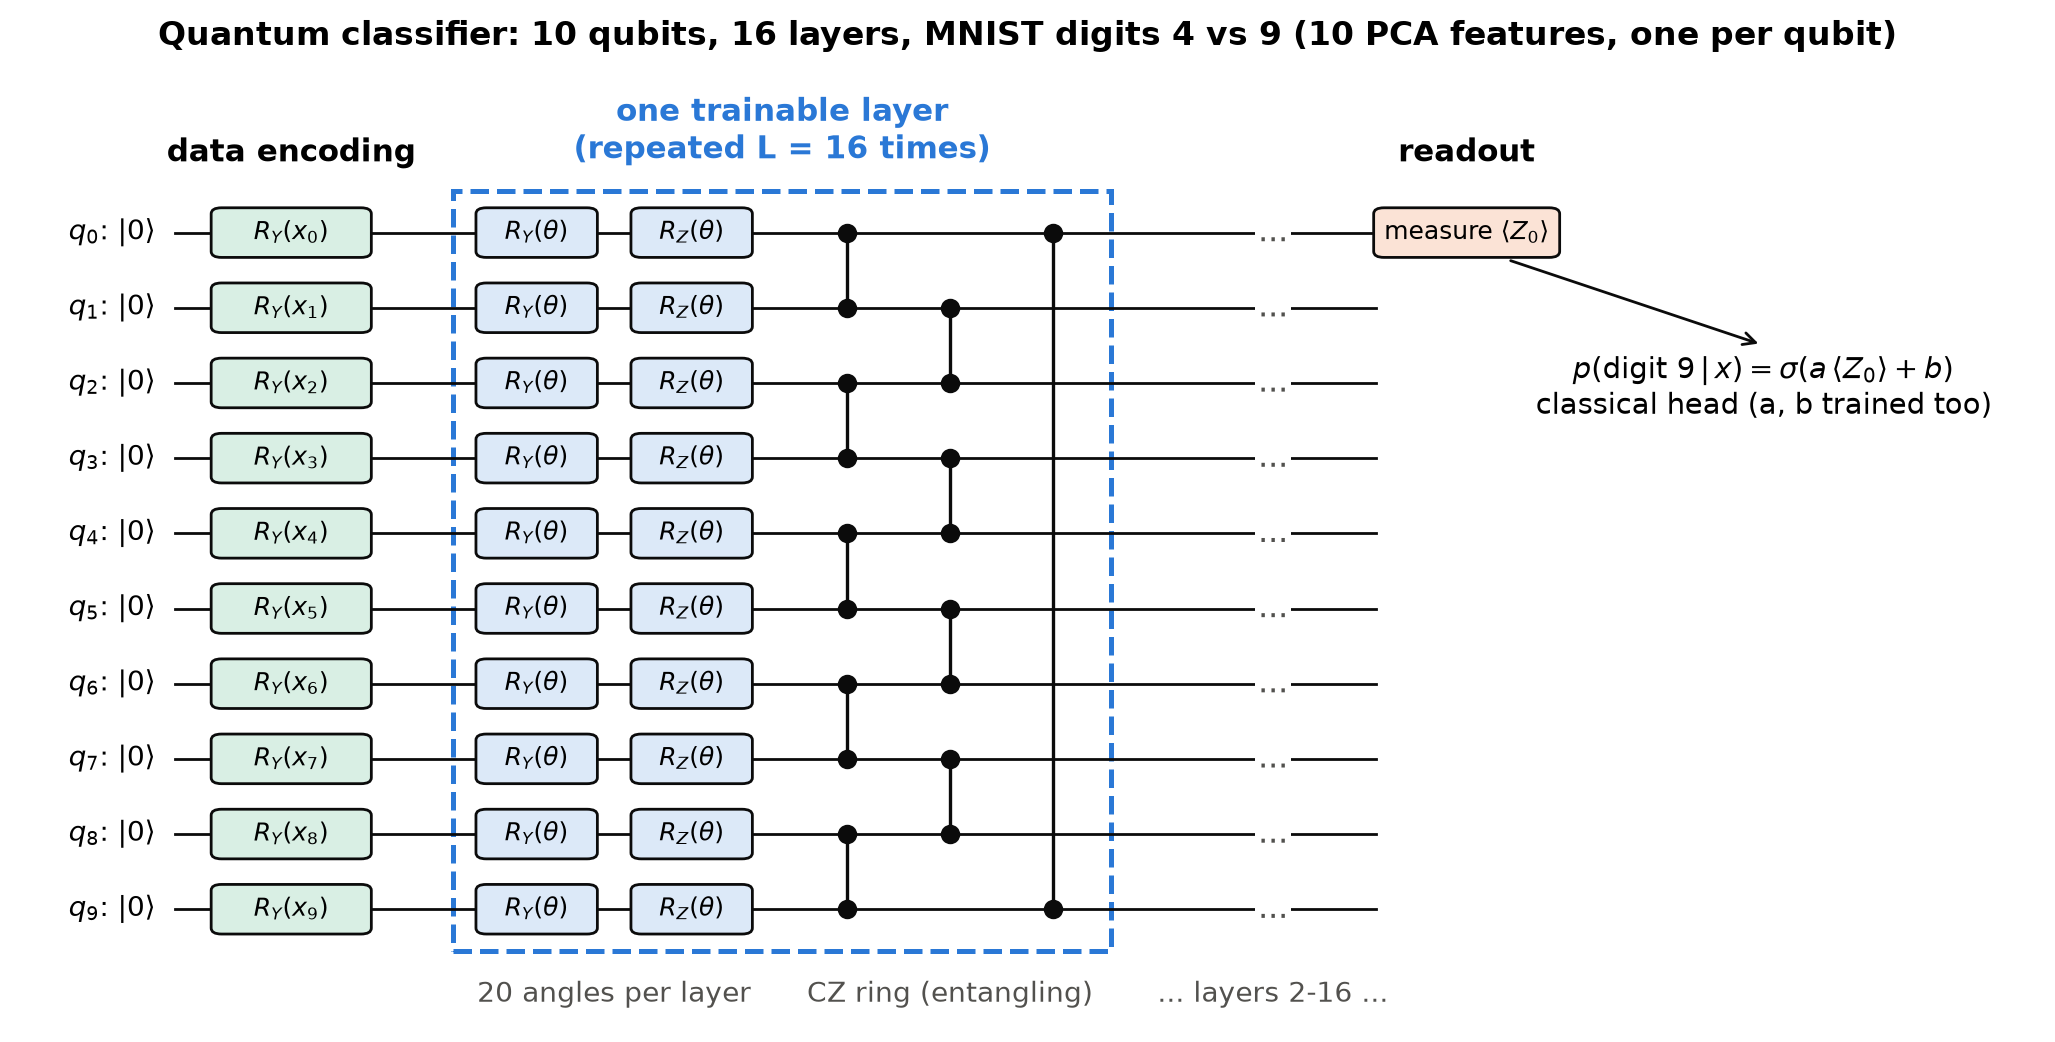

In [3]:
display(Image(str(C.FIGURES / "fig1_circuit.png"), width=950))

In [4]:
# PennyLane model (src/circuit.py). Training uses a fast simulator of the same circuit (src/fastsim.py);
# both must give identical outputs.
L, n = C.TASK["n_layers"], C.TASK["n_qubits"]
qnode = make_qnode(n, L, cost="local")
w = init_weights("direct", L, n, seed=0)
x = split.x_test[:4]
pl = qnode(torch.tensor(x), torch.tensor(w)).detach().numpy()
fast = Engine(n, "local").expval(torch.tensor(x), torch.tensor(w)).numpy()
print("PennyLane <Z0>:", np.round(pl, 6))
print("fast sim  <Z0>:", np.round(fast, 6))
print("max difference:", float(np.abs(pl - fast).max()))
print("trainable parameters:", w.size, "circuit angles + 2 (a, b)")

PennyLane <Z0>: [0.018364 0.103707 0.03873  0.072644]
fast sim  <Z0>: [0.018364 0.103707 0.03873  0.072644]
max difference: 3.469446951953614e-16
trainable parameters: 320 circuit angles + 2 (a, b)


## 3. The two training schemes (O2): same budget of 320 Adam updates

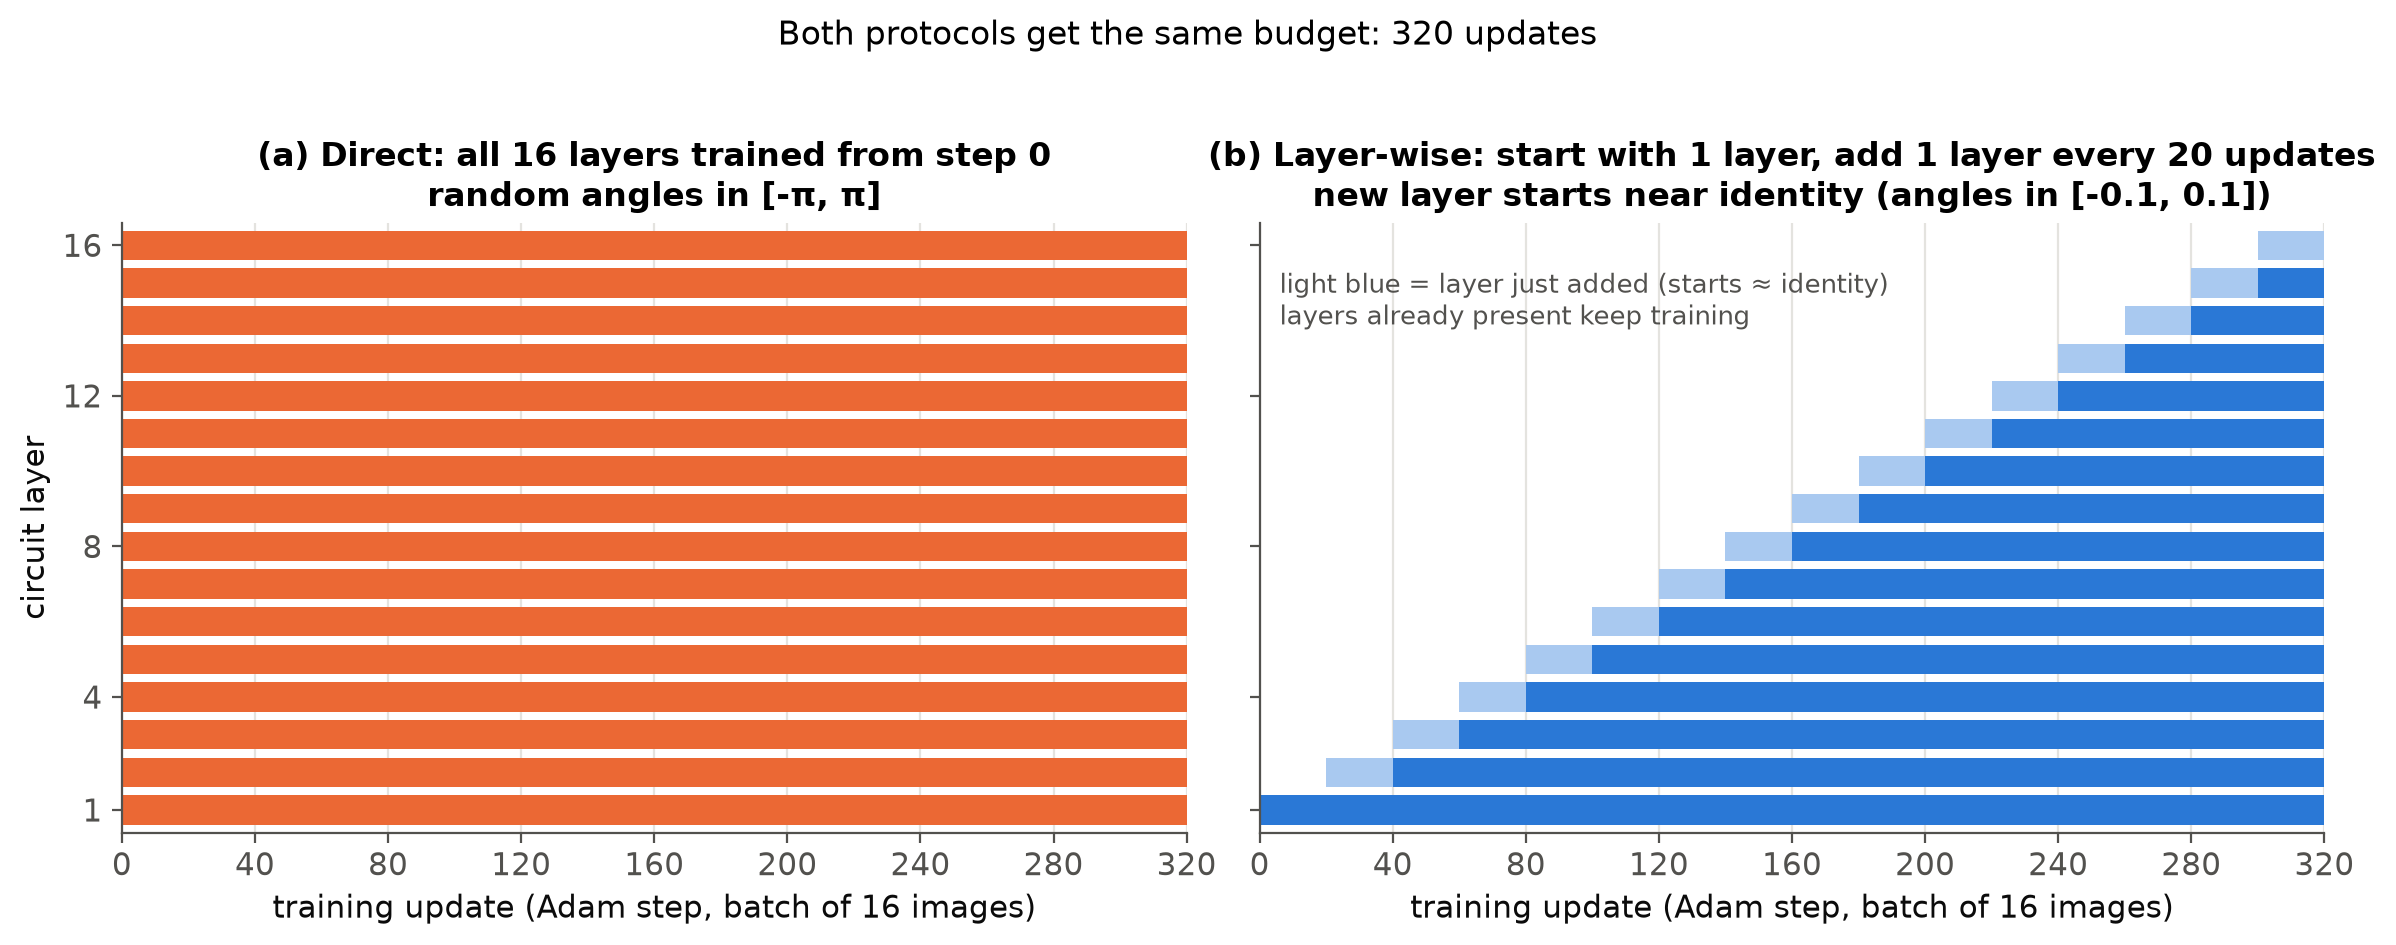

In [5]:
display(Image(str(C.FIGURES / "fig2_training_schemes.png"), width=950))

In [6]:
for m in ("direct", "ll"):
    st = schedule(m, L, C.TRAIN["updates_per_stage"])
    print(f"{m:6s}: {len(st):2d} stage(s), (depth, updates) =", [(d, u) for d, _, u in st][:4],
          "..." if len(st) > 4 else "")

direct:  1 stage(s), (depth, updates) = [(16, 320)] 
ll    : 16 stage(s), (depth, updates) = [(1, 20), (2, 20), (3, 20), (4, 20)] ...


**Optional live training.** Set `RUN_DEMO = True` to train seed 0 of both schemes from scratch
(noiseless, about 2-4 minutes). The result matches the saved run, which shows the saved results are
reproducible.

In [7]:
RUN_DEMO = False
for m in ("direct", "ll"):
    saved = json.loads((C.RESULTS / "runs" / "noiseless" / m / "seed_000.json").read_text())["summary"]
    if RUN_DEMO:
        new = train_run(make_cfg("noiseless", m, 0)[1])["summary"]
        print(f"{m:6s}: retrained test acc {new['final_test_acc']:.4f} | saved {saved['final_test_acc']:.4f}")
    else:
        print(f"{m:6s}: saved test acc {saved['final_test_acc']:.4f} (set RUN_DEMO = True to retrain)")

direct: saved test acc 0.9300 (set RUN_DEMO = True to retrain)
ll    : saved test acc 0.9125 (set RUN_DEMO = True to retrain)


## 4. Results (O3)

In [8]:
runs = F.load_all()
table = pd.DataFrame(F.summarize(runs)).rename(columns={
    "setting": "noise", "mean_test_acc": "test acc", "ci95_test_acc": "±95% CI",
    "mean_final_train_loss": "train loss", "successful_runs": "successes",
    "success_rate_pct": "success %", "runs_reaching_90pct": "reached 90%",
    "median_iters_to_90pct": "median iters to 90%"})
table["method"] = table["method"].map(F.METHODS)
table

,noise,method,runs,test acc,±95% CI,train loss,successes,success %,reached 90%,median iters to 90%
0,noiseless,Direct,30,0.9195,0.0091,0.2344,25,83.3,30,58.0
1,noiseless,Layer-wise (LL),30,0.8869,0.0113,0.3715,3,10.0,25,264.0
2,shots1000,Direct,30,0.9136,0.0086,0.2528,23,76.7,30,65.0
3,shots1000,Layer-wise (LL),30,0.7937,0.0211,0.4965,0,0.0,4,285.0
4,shots500,Direct,30,0.9057,0.0119,0.2619,23,76.7,30,71.0
5,shots500,Layer-wise (LL),30,0.7931,0.0175,0.5084,0,0.0,1,298.0


**Is the difference real?** Paired comparison over the 30 seeds (same seed = same first layer and same batches).

In [9]:
for s in F.SETTINGS:
    d = np.array([r["summary"]["final_test_acc"] for r in runs[(s, "direct")]])
    l = np.array([r["summary"]["final_test_acc"] for r in runs[(s, "ll")]])
    sd = sum(r["summary"]["success"] for r in runs[(s, "direct")])
    sl = sum(r["summary"]["success"] for r in runs[(s, "ll")])
    print(f"{s:9s}: Direct better in {(d > l).sum()}/30 seeds, Wilcoxon p = {wilcoxon(d, l).pvalue:.1e}, "
          f"success Fisher p = {fisher_exact([[sd, 30 - sd], [sl, 30 - sl]]).pvalue:.1e}")

noiseless: Direct better in 28/30 seeds, Wilcoxon p = 3.3e-06, success Fisher p = 1.1e-08
shots1000: Direct better in 30/30 seeds, Wilcoxon p = 1.7e-06, success Fisher p = 1.7e-10
shots500 : Direct better in 30/30 seeds, Wilcoxon p = 1.7e-06, success Fisher p = 1.7e-10


### Test accuracy during training

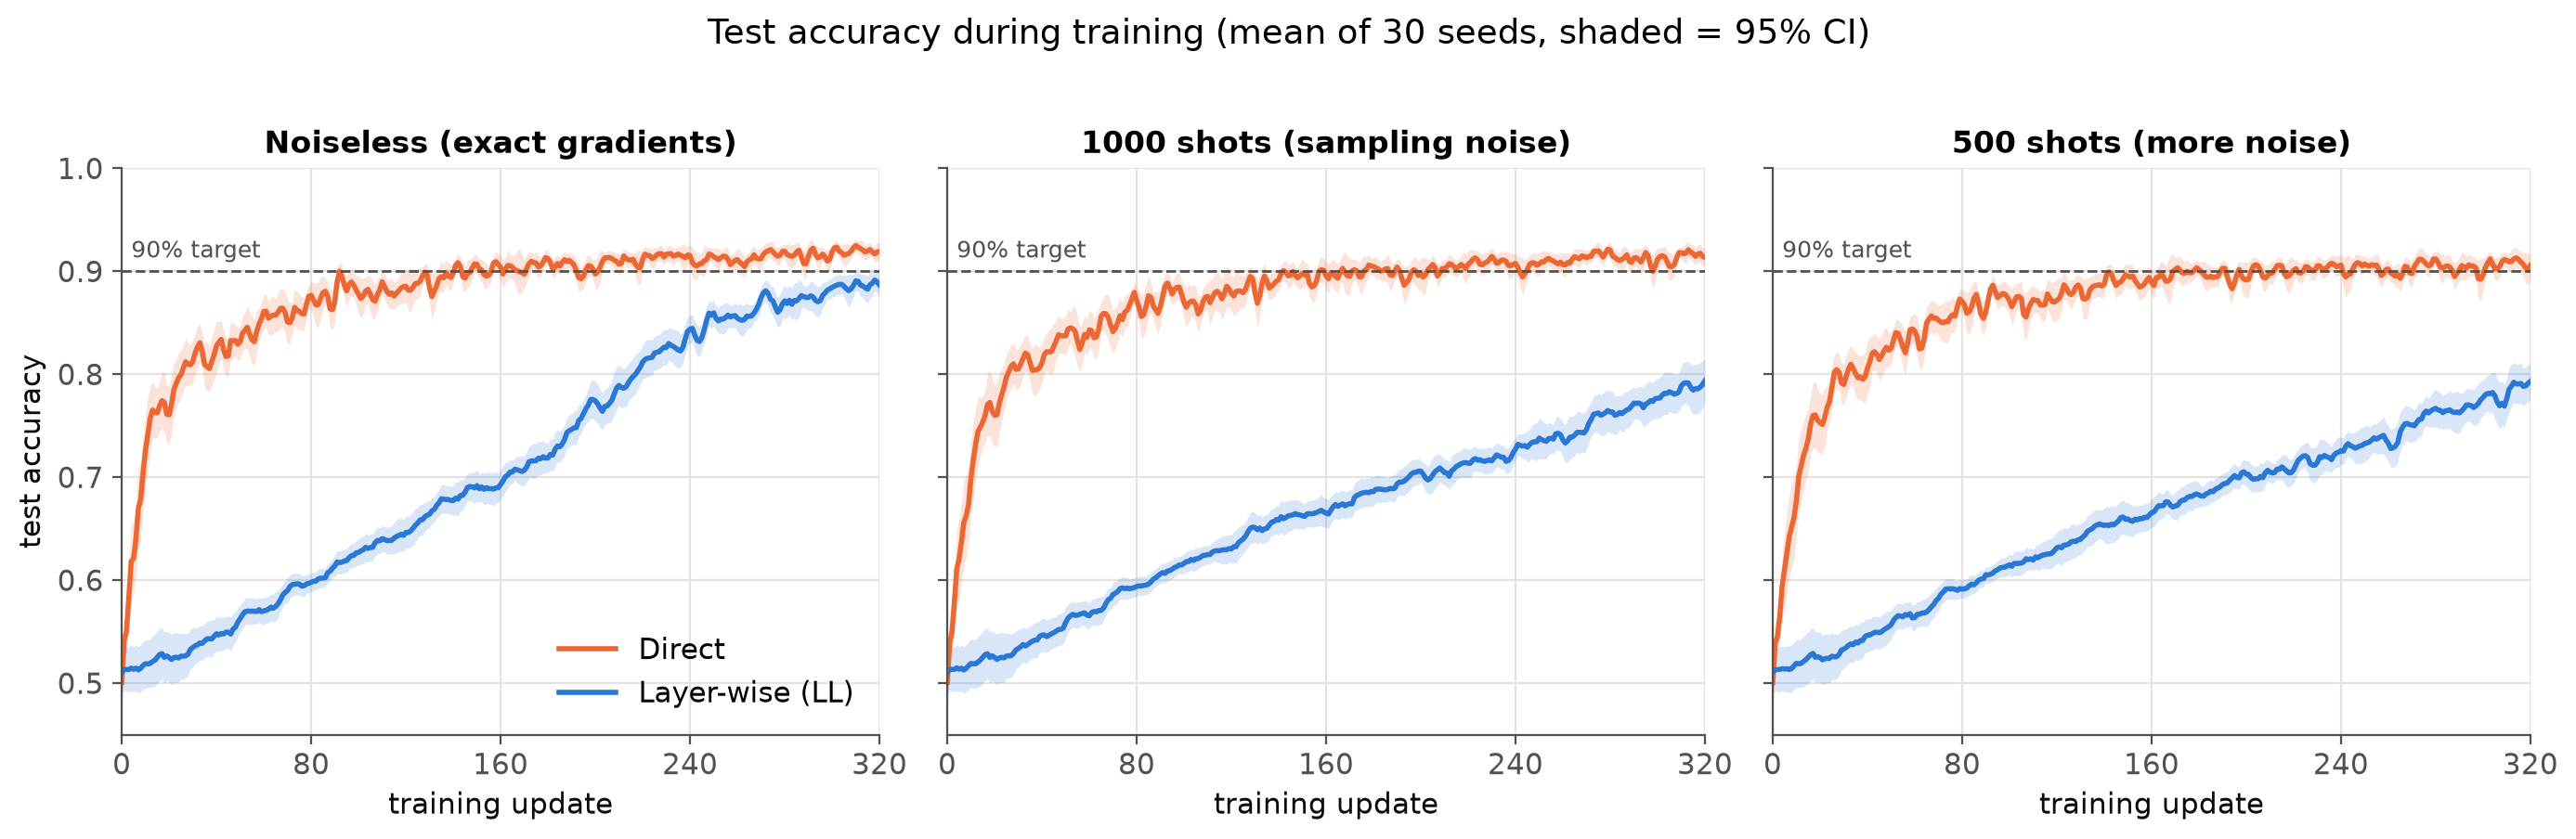

In [10]:
display(Image(str(C.FIGURES / "fig4_test_accuracy_curves.png"), width=1000))

### Final test accuracy and sensitivity to sampling noise

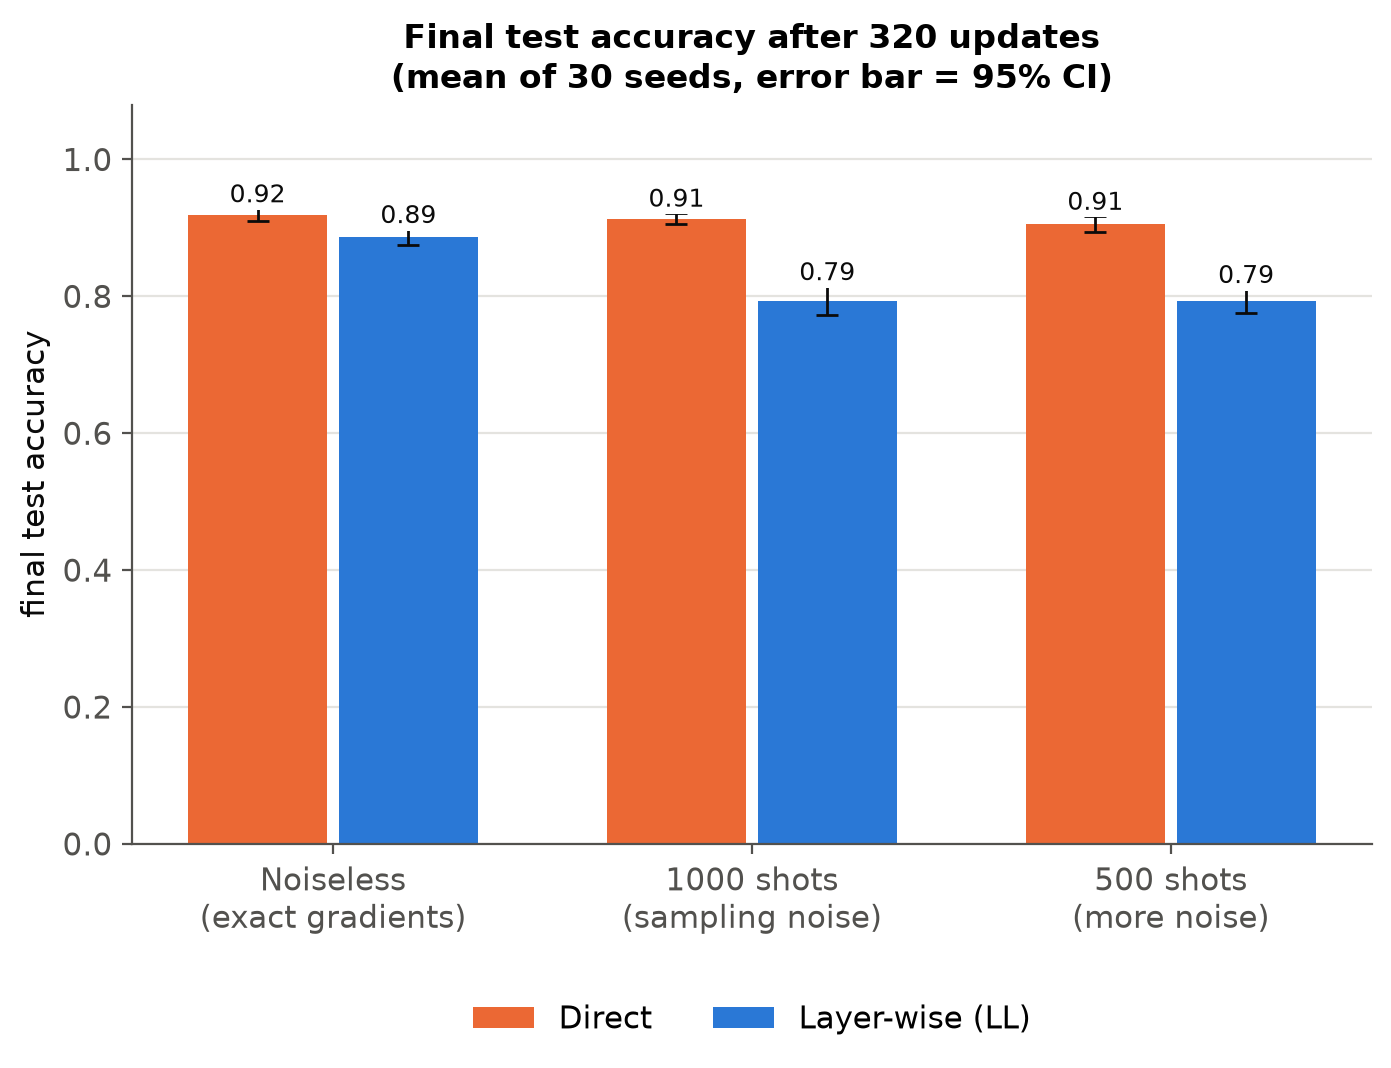

In [11]:
display(Image(str(C.FIGURES / "fig5_final_accuracy.png"), width=650))

### Percentage of successful runs

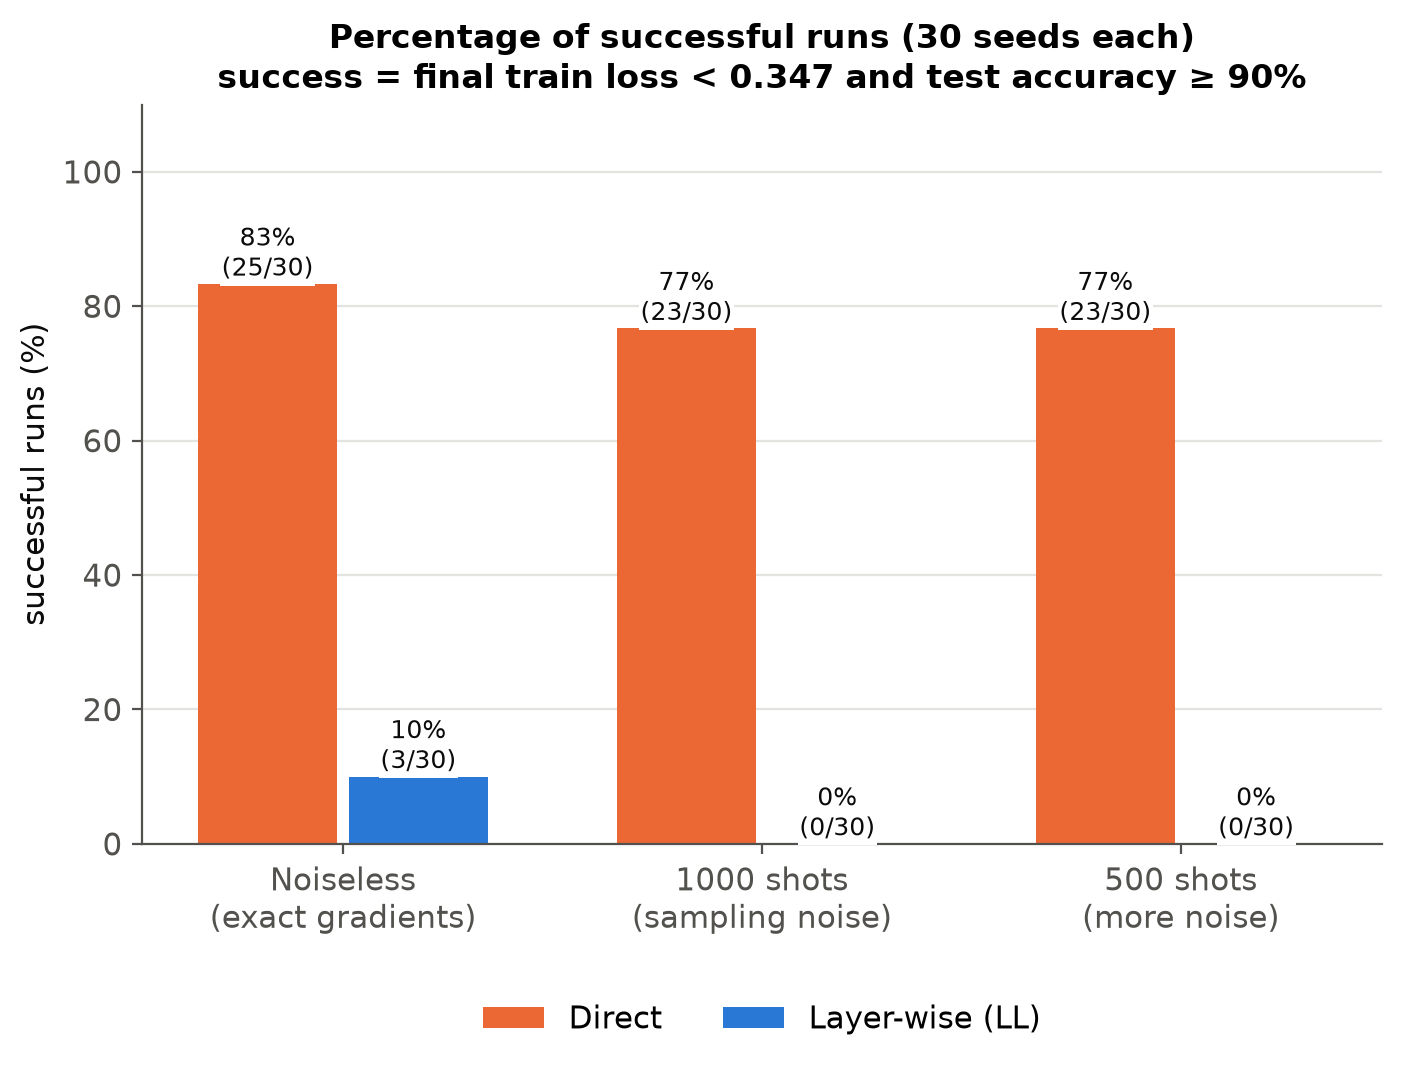

In [12]:
display(Image(str(C.FIGURES / "fig6_success_rate.png"), width=650))

### Iterations to converge

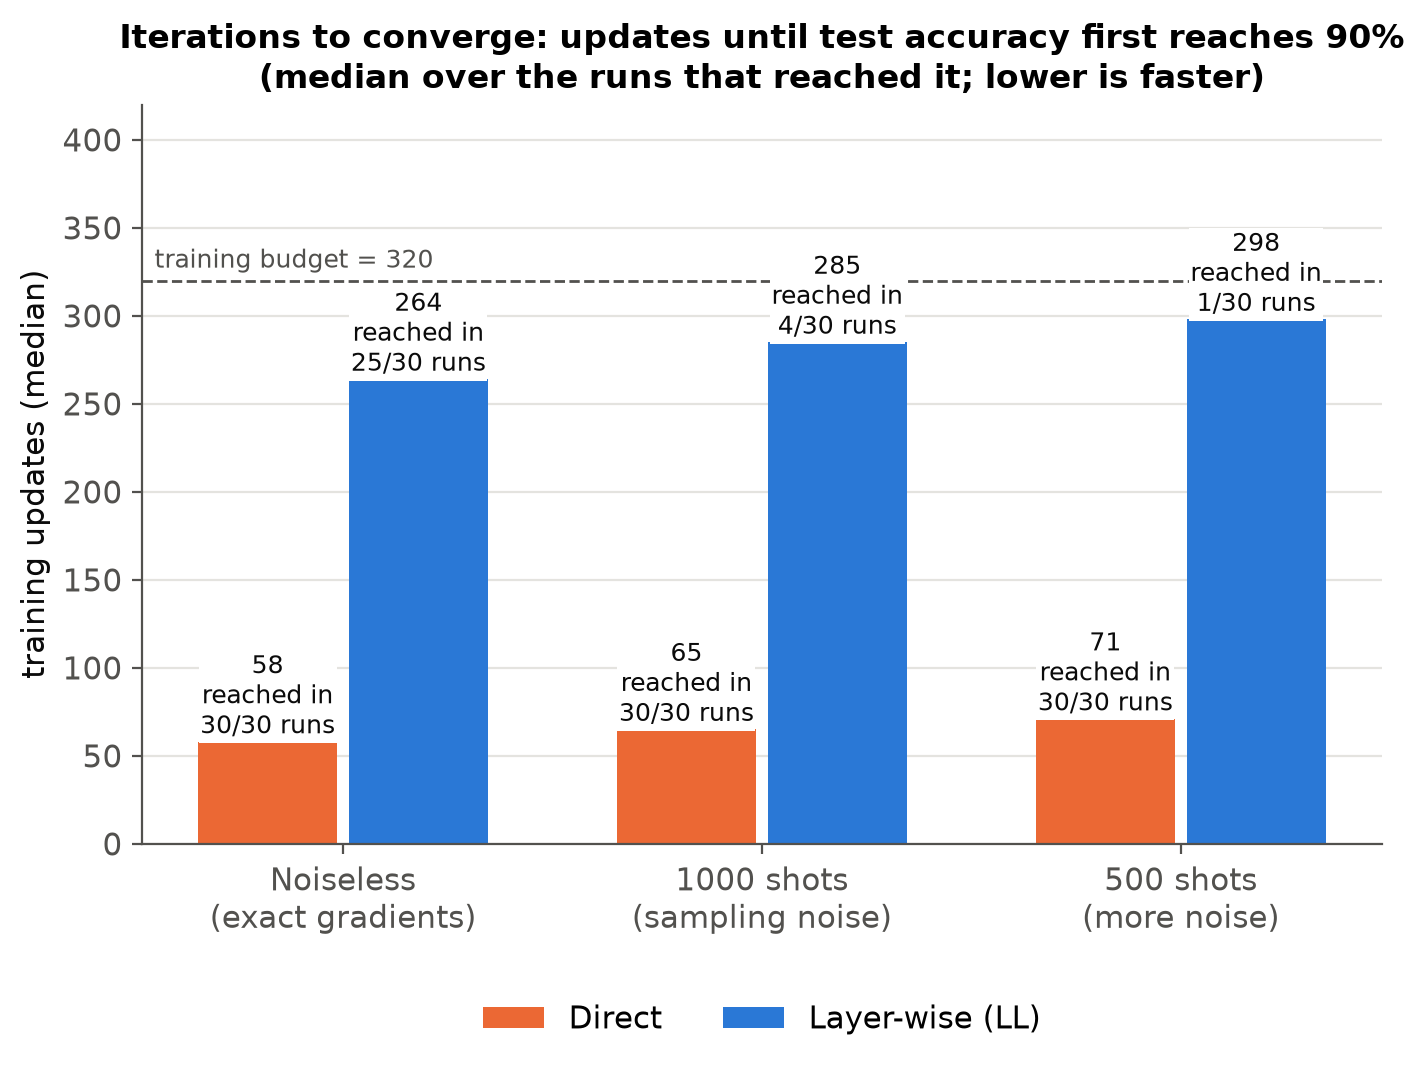

In [13]:
display(Image(str(C.FIGURES / "fig7_iterations_to_converge.png"), width=650))

## 5. Barren-plateau diagnostic

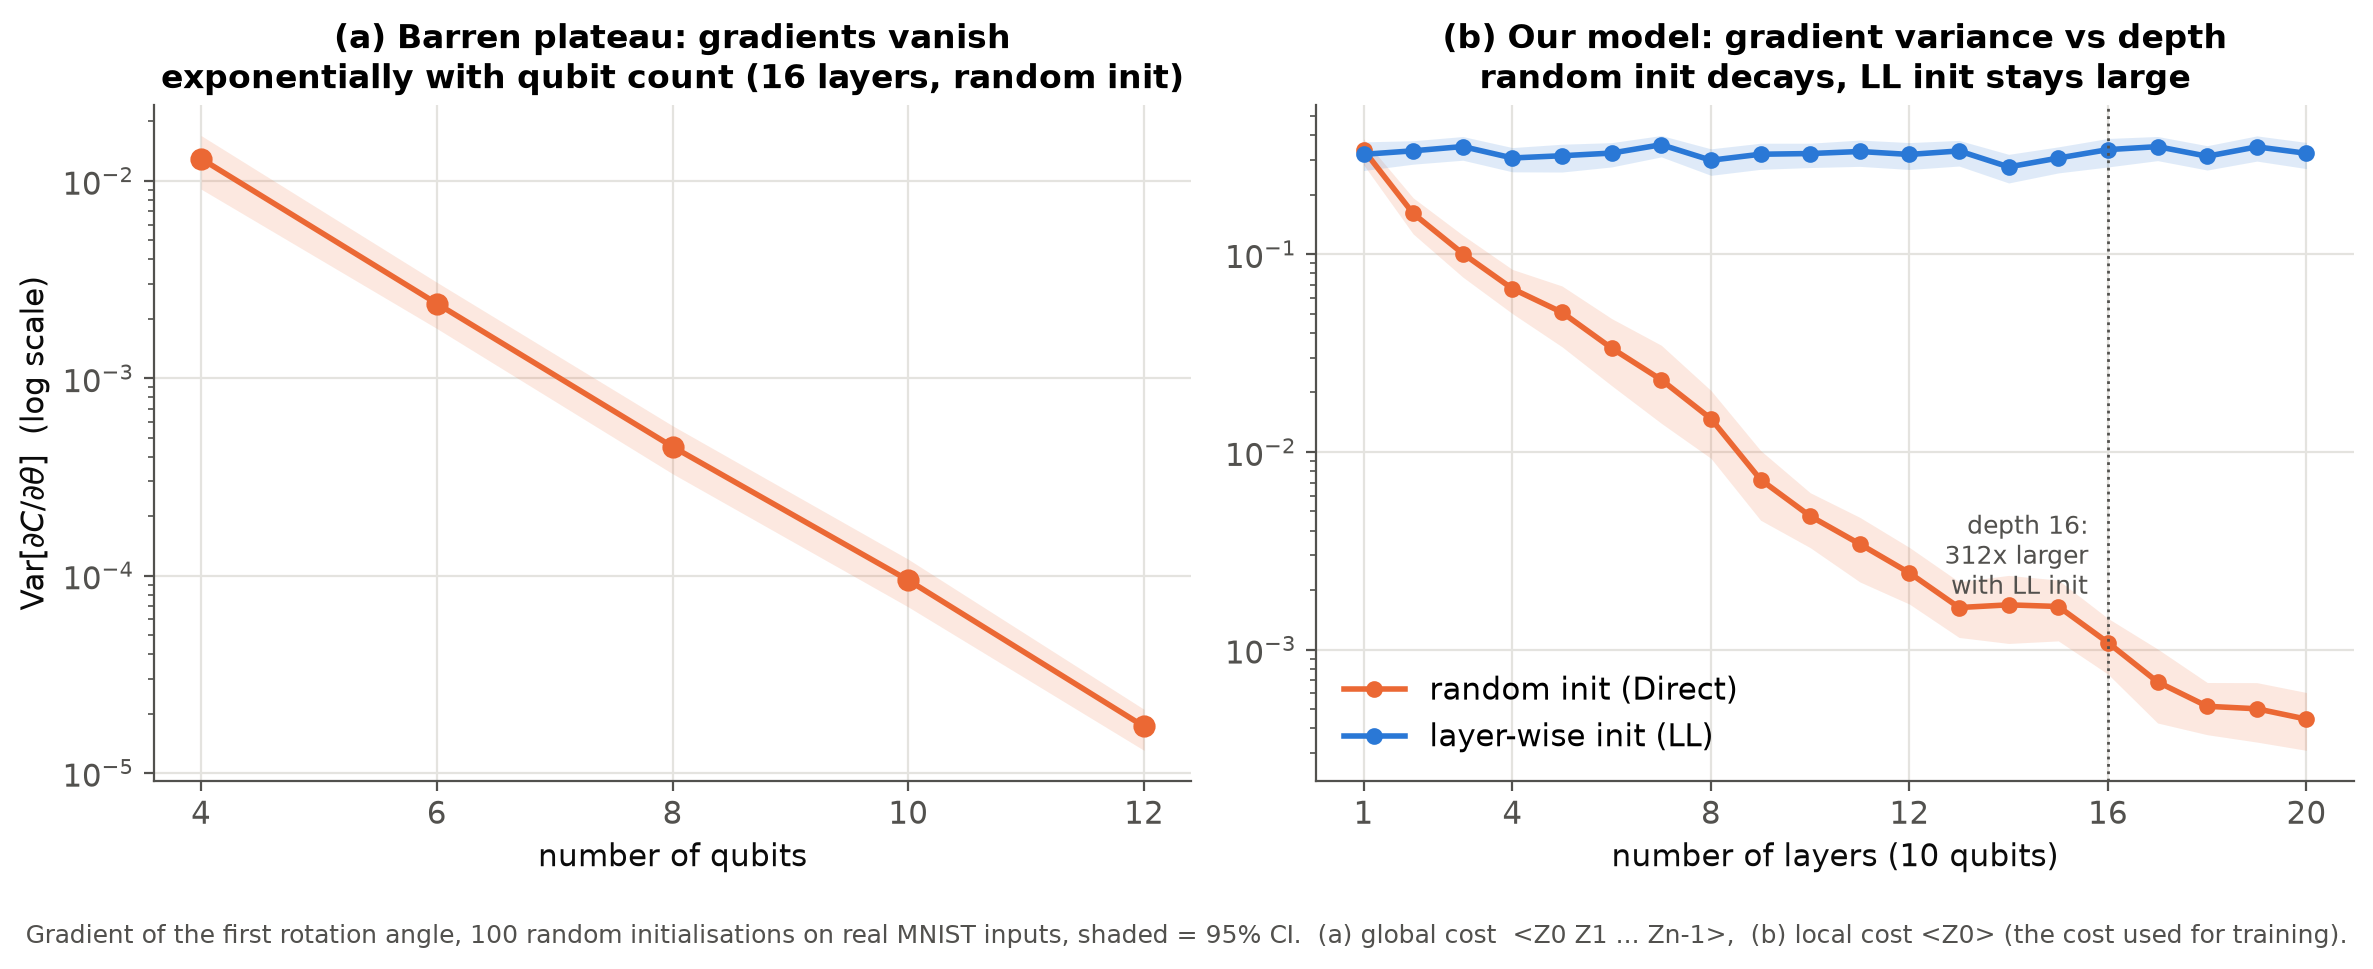

In [14]:
display(Image(str(C.FIGURES / "fig3_barren_plateau.png"), width=1000))

In [15]:
# Per-parameter gradient size during training (noiseless): smaller gradients are easier to drown in shot noise
for m in ("direct", "ll"):
    at = [20, 40, 100, 200]
    g = np.array([[r["history"]["grad_mean_abs_trainable"][i] for i in at] for r in runs[("noiseless", m)]])
    print(f"{m:6s}: mean |gradient| per parameter at updates {at} =", np.round(g.mean(0), 4))

direct: mean |gradient| per parameter at updates [20, 40, 100, 200] = [0.0041 0.0068 0.0136 0.0184]
ll    : mean |gradient| per parameter at updates [20, 40, 100, 200] = [0.0023 0.0018 0.0027 0.0057]


## 6. Conclusion

* **Barren plateau confirmed:** with random initialisation the gradient variance falls about 300x from 1 to 16
  layers; the layer-wise initialisation keeps it large (Fig. 3). This is why LL is proposed.
* **In training, Direct won** at this size (10 qubits, 16 layers): higher accuracy, faster convergence, more
  successful runs, and almost no loss under 500-1000 shots, while LL dropped from 0.89 to 0.79.
* **Why:** Direct is not stuck on a plateau here; shallow LL stages can only see 2d - 1 of the 10 features
  and spend most of the budget below full depth; LL's smaller gradients suffer more from shot noise.
  Details: `README.md`, Section 7.